# Neuron Lab 02: From Spikes to Synapses

### How does the activity of one neuron change the behavior of another?

In Lab 01, we studied a single neuron: how it integrates input, reaches a threshold, and produces spikes. But neurons do not work in isolation. A spike can travel to a connection called a **synapse** and influence another neuron.

This lab begins with a simple question:

> If neuron A fires, will neuron B fire too?

We will discover that the answer depends on more than whether a spike occurred. The **strength**, **timing**, and **type** of synaptic input all matter.

We will build small circuits in Brian2 and investigate three questions:

1. Can a single incoming spike make another neuron fire?
2. Can two individually weak inputs succeed when they arrive close together?
3. Can an inhibitory input prevent a spike that would otherwise occur?

By the end, we will have moved from understanding one neuron to understanding the first building block of a neural circuit.

> **Modeling note:** These are deliberately simplified neurons and synapses. Their purpose is to reveal mechanisms, not to reproduce every detail of a biological circuit.

## Before the Simulation: What Crosses a Synapse?

A spike in neuron A does **not** simply jump across an empty gap and become a spike in neuron B.

At a typical **chemical synapse**, the sequence is:

1. An action potential reaches the end of neuron A's axon.
2. Calcium enters the presynaptic terminal.
3. This triggers the release of chemical messengers called **neurotransmitters**.
4. Neurotransmitters bind to receptors on neuron B.
5. The resulting change in ion flow affects neuron B's membrane voltage—and therefore its chance of firing.

Neuron A is the **presynaptic neuron** (the sender). Neuron B is the **postsynaptic neuron** (the receiver).

The crucial distinction is this:

> A presynaptic spike is an event. Its postsynaptic effect is usually a change in the receiving neuron's state—not a guaranteed new spike.

Depending on the synapse, that effect may make the receiver **more likely** or **less likely** to fire. In this lab, we will begin with a deliberately simplified synapse: when a spike arrives, it produces a small change in the receiving neuron's voltage. Later, we will test when that small change is enough to produce a new spike.

**Prediction:** If one incoming spike causes a voltage change that is too small to reach threshold, what might happen if two such spikes arrive close together?

*Biological background: [Chemical Synapses — Neuroscience, NCBI Bookshelf](https://www.ncbi.nlm.nih.gov/books/NBK11009/).*

In [1]:
!pip -q install brian2

import brian2

print(f"Brian2 version: {brian2.__version__}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 27.6 MB/s eta 0:00:00
Brian2 version: 2.10.1


## Experiment 1 — Is One Incoming Spike Enough?

We will begin with the smallest possible communication experiment.

A **controlled spike source** represents neuron A. It emits exactly one spike at **20 ms**. The spike reaches neuron B through an excitatory synapse after a **2 ms delay**.

Neuron B starts at **−65 mV** and fires only if its voltage reaches **−50 mV**. When the incoming spike arrives, our simplified synapse increases B's voltage by **6 mV**.

Before running the simulation, make a prediction:

> Will neuron B fire? At what time should its voltage begin to change?

**Modeling choice:** For now, we prescribe A's spike rather than simulate A's membrane. This lets us isolate one question: *what does that spike do to B?* We also model the synapse as an instantaneous voltage change; real chemical synapses have more detailed dynamics.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from brian2 import (
    SpikeGeneratorGroup,
    NeuronGroup,
    Synapses,
    StateMonitor,
    SpikeMonitor,
    defaultclock,
    start_scope,
    run,
    ms,
    mV,
)

start_scope()
defaultclock.dt = 0.1 * ms

# Neuron A: a controlled source that emits one spike at 20 ms.
sender = SpikeGeneratorGroup(
    1,
    indices=np.array([0]),
    times=np.array([20.0]) * ms,
)

# Neuron B: the same basic LIF idea used in Lab 01.
receiver_parameters = {
    "V_REST": -65 * mV,
    "V_THRESHOLD": -50 * mV,
    "TAU_M": 10 * ms,
}

receiver = NeuronGroup(
    1,
    model="dv/dt = (V_REST - v) / TAU_M : volt",
    threshold="v >= V_THRESHOLD",
    reset="v = V_REST",
    method="exact",
    namespace=receiver_parameters,
)
receiver.v = receiver_parameters["V_REST"]

# Each arriving presynaptic spike adds 'weight' to B's voltage.
synapse = Synapses(
    sender,
    receiver,
    model="weight : volt",
    on_pre="v_post += weight",
)
synapse.connect()
synapse.weight = 6 * mV
synapse.delay = 2 * ms

sender_spikes = SpikeMonitor(sender)
receiver_spikes = SpikeMonitor(receiver)
receiver_voltage = StateMonitor(receiver, "v", record=True)

run(70 * ms)

print(f"Spikes sent by A: {sender_spikes.num_spikes}")
print(f"Spikes produced by B: {receiver_spikes.num_spikes}")

Spikes sent by A: 1
Spikes produced by B: 0


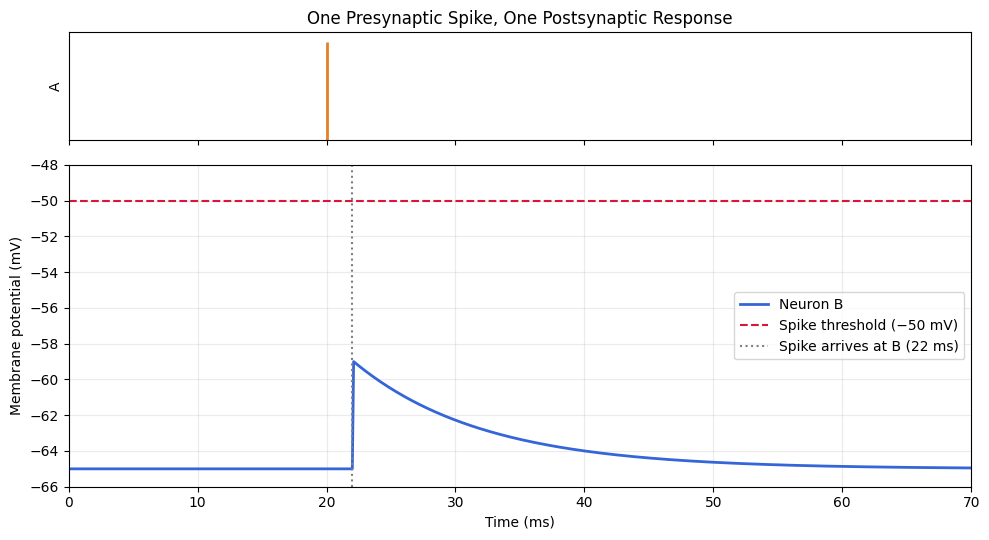

In [3]:
fig, axes = plt.subplots(
    2, 1, figsize=(10, 5.5), sharex=True,
    gridspec_kw={"height_ratios": [1, 3]},
)

# The spike emitted by A.
axes[0].vlines(sender_spikes.t / ms, 0, 1, color="#e67e22", linewidth=2)
axes[0].set_ylim(0, 1.1)
axes[0].set_yticks([])
axes[0].set_ylabel("A")
axes[0].set_title("One Presynaptic Spike, One Postsynaptic Response")

# The voltage of B.
axes[1].plot(
    receiver_voltage.t / ms,
    receiver_voltage.v[0] / mV,
    color="#3465d9",
    linewidth=2,
    label="Neuron B",
)
axes[1].axhline(
    -50, color="crimson", linestyle="--",
    label="Spike threshold (−50 mV)",
)
axes[1].axvline(
    22, color="gray", linestyle=":",
    label="Spike arrives at B (22 ms)",
)

axes[1].set_xlim(0, 70)
axes[1].set_ylim(-66, -48)
axes[1].set_xlabel("Time (ms)")
axes[1].set_ylabel("Membrane potential (mV)")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

## What Happened?

Neuron A fired at **20 ms**, but neuron B did not respond immediately. The synaptic signal arrived **2 ms later**, at approximately **22 ms**.

B's voltage rose from **−65 mV** to approximately **−59 mV**:

**−65 mV + 6 mV = −59 mV**

That is still below the **−50 mV** spike threshold, so B produced **no spike**. Afterward, its voltage gradually returned toward the resting value because of membrane leak.

> **Key insight:** Receiving a spike is not the same as producing one. A synaptic message can change a neuron's state without making it fire.

This raises our next question: **Could two individually insufficient messages make B fire if they arrive close together?**